In [1]:
# !export PYTHONPATH="/usr/local/cuda/nsight-compute-2022.1.0/extras/python"
import sys
sys.path.append("/usr/local/cuda/nsight-compute-2022.1.0/extras/python")

In [2]:
import ncu_report
my_context = ncu_report.load_report("/home/enerd/parallel_cuda/project_data/nn1024_full.ncu-rep")

In [1]:
def avr_metric_by_nvtx_range(report, nvtx_range, metric, verbose=False):
    assert report.num_ranges()==1
    my_range = report.range_by_idx(0)
    arr=[]
    prev_i=0
    for i in range(my_range.num_actions()):
        kernel=my_range.action_by_idx(i)
        
        try:
            if kernel.nvtx_state().domain_by_id(0).push_pop_ranges()[0]==nvtx_range:
                val=kernel.metric_by_name(metric).as_double()
                if verbose:
                    print(f"{i-prev_i})", val)
                arr.append(val)
                prev_i=i
        except:
            pass
    
    return sum(arr)/len(arr)

def avr_metric_by_kernel_name(report, kernel_name, metric, verbose):
    assert report.num_ranges()==1
    my_range = report.range_by_idx(0)
    arr=[]
    prev_i=0
    for i in range(my_range.num_actions()):
        kernel=my_range.action_by_idx(i)
        
        if kernel.name().find(kernel_name) !=-1:
            val=kernel.metric_by_name(metric).as_double()
            arr.append(val)
            if verbose:
                print(f"{i-prev_i})", kernel.name(), val)    
            prev_i=i

    return sum(arr)/len(arr)  



In [12]:
# Metrics of interest


achieved_occupancy="sm__warps_active.avg.pct_of_peak_sustained_active"
l1_hit_rate="l1tex__t_sector_hit_rate.pct"  	
l2_hit_rate="lts__t_sector_hit_rate.pct"
compute_throughput="sm__throughput.avg.pct_of_peak_sustained_elapsed"
memory_throughput="gpu__compute_memory_throughput.avg.pct_of_peak_sustained_elapsed"

no_eligible="smsp__issue_inst0.avg.pct_of_peak_sustained_active"
eligible="smsp__issue_active.avg.pct_of_peak_sustained_active"

In [28]:
a=avr_metric_by_nvtx_range(my_context, "Linear", l1_hit_rate)

38) 3.4230760708192074
45) 3.4345296932785465
45) 3.362664244194677
45) 3.4649024444942813
45) 3.451985135928027
45) 3.3952800747909793
45) 3.5484090030027726
45) 3.444108939851445
45) 3.498686109391917
45) 3.445524423652629
45) 3.4698726112767537
45) 3.379129376906421
45) 3.5350672052535845
45) 3.3755636167893845
45) 3.3073532287019427


In [29]:
avr_metric_by_kernel_name(my_context, "indexSelect", l1_hit_rate)

39) indexSelectLargeIndex 30.601874357347064
45) indexSelectLargeIndex 30.641276410814775
45) indexSelectLargeIndex 30.583667436209478
45) indexSelectLargeIndex 30.66334104373653
45) indexSelectLargeIndex 30.599911480893432
45) indexSelectLargeIndex 30.58278592152675
45) indexSelectLargeIndex 30.640387999584597
45) indexSelectLargeIndex 30.657673561232397
45) indexSelectLargeIndex 30.656618885256442
45) indexSelectLargeIndex 30.63904913227624
45) indexSelectLargeIndex 30.65738793321201
45) indexSelectLargeIndex 30.64459618064902
45) indexSelectLargeIndex 30.63931336200935
45) indexSelectLargeIndex 30.657877952452246
45) indexSelectLargeIndex 30.65762837602875


30.634892668881943

In [9]:
for i in range(my_range.num_actions()):
    a=my_range.action_by_idx(i)
    print(a.name())
    if i>10:
        break

vectorized_elementwise_kernel
vectorized_elementwise_kernel
elementwise_kernel_with_index
elementwise_kernel
vectorized_elementwise_kernel
vectorized_elementwise_kernel
DeviceReduceKernel
DeviceReduceSingleTileKernel
DeviceCompactInitKernel
DeviceSelectSweepKernel
index_elementwise_kernel
DeviceReduceKernel


In [26]:
c=b.domain_by_id(0)
c.push_pop_ranges()[0]


'Normalize'

In [48]:
for i in range(my_range.num_actions()):
    kernel=my_range.action_by_idx(i)
    
    try:
        if kernel.nvtx_state().domain_by_id(0).push_pop_ranges()[0]=="Linear":
            print(kernel.name(), kernel.metric_by_name("sm__warps_active.avg.pct_of_peak_sustained_active").as_double())
    except:
        pass

ampere_sgemm_32x128_tn 62.83267585257348
ampere_sgemm_32x128_tn 62.373721566868255
ampere_sgemm_32x128_tn 62.28356754437804
ampere_sgemm_32x128_tn 62.5028938996641
ampere_sgemm_32x128_tn 62.58101427813333
ampere_sgemm_32x128_tn 62.43754006720702
ampere_sgemm_32x128_tn 62.441421478795704
ampere_sgemm_32x128_tn 62.27818629149097
ampere_sgemm_32x128_tn 62.251401901457825
ampere_sgemm_32x128_tn 62.99795716452232
ampere_sgemm_32x128_tn 62.60137958627412
ampere_sgemm_32x128_tn 62.43790821157056
ampere_sgemm_32x128_tn 62.31514767897309
ampere_sgemm_32x128_tn 63.23246043158471
ampere_sgemm_32x128_tn 62.388684462537306
ampere_sgemm_32x128_tn 63.12564166989626


In [46]:
m=kernel.metric_by_name("sm__warps_active.avg.pct_of_peak_sustained_active")
m

82

In [ ]:
for range_idx in range(my_context.num_ranges()):
    current_range = my_context.range_by_idx(range_idx)
    print("current_range:", current_range)
    # for action_idx in current_range.actions_by_nvtx(["BottomRange/*/TopRange"], []):
    #     print("action_idx:", action_idx)
    #     action = current_range.action_by_idx(action_idx)
    #     print(action.name())
    #     print(action.metric_by_name("gpc__cycles_elapsed.sum").as_uint64())  
    for action_idx in range(current_range.num_actions()):
        action=current_range.action_by_idx(action_idx)
        # print(action.metric_by_name("gpc__cycles_elapsed.sum").as_uint64()) 
        # for m in action.metric_names():
        #     if "stall_reason" in m:
        #         print(m)

        met=action.metric_by_name("group:smsp__pcsamp_warp_stall_reasons")
        print(met.as_uint64())

In [63]:
asd=action.metric_by_name("group:smsp__pcsamp_warp_stall_reasons")

asd.as_uint64()

0

In [25]:
current_range.actions_by_nvtx(includes=[])

TypeError: actions_by_nvtx() missing 2 required positional arguments: 'includes' and 'excludes'

In [33]:
report=my_context

for range_idx in range(report.num_ranges()):
    current_range = report.range_by_idx(range_idx)
    for action_idx in current_range.actions_by_nvtx(["BottomRange/*/TopRange"], []):
        action = current_range.action_by_idx(action_idx)
        print(action.name())


In [39]:
current_range.actions_by_nvtx(["BottomRange/Linear/TopRange"], [])

()

In [ ]:
import os
from natsort import natsorted
experiments_names=[e for e in os.listdir(".") if e.startswith("exp_nn")]
experiments_names=natsorted(experiments_names)

normalize={}
linear={}
propagate={}

# data_nn={exp:[normalize[exp], linear[exp], propagate[exp]] for exp in experiments}

metrics_to_collect=[l1_hit_rate, l2_hit_rate, achieved_occupancy, memory_throughput, compute_throughput]

for m in metrics_to_collect:
    normalize[m]={}
    linear[m]={}
    propagate[m]={}
    for exp in experiments_names:
        normalize[m][exp]=avr_metric_by_nvtx_range(exp, "Normalize", m)
        linear[m][exp]=avr_metric_by_nvtx_range(exp, "Linear", m)
        propagate[m][exp]=avr_metric_by_nvtx_range(exp, "Propagate", m)



In [1]:
import argparse
import cProfile
import random
import subprocess
import sys
import time

import numpy as np
# import nvtx
import torch
import torch.nn as nn

from torch.profiler import profile, record_function, ProfilerActivity
from torch.nn import CrossEntropyLoss
from torch.optim import Adam
import torch_geometric as pyg
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

from model import GCN_Model
from utils import get_minutes, get_random_graph, get_random_barabasi_albert_graph, save_graph_img, save_node_degree_dist, get_unique_path

import matplotlib.pyplot as plt
N=5000
data1 = get_random_graph(N, 0.1, 1, 1)
# data2 = get_random_barabasi_albert_graph(N, 0.1, 1, 1)


plt.figure()
from torch_geometric.utils import to_dense_adj, degree, add_self_loops
from torch_geometric.data import Data, Dataset, download_url, extract_zip

degrees=degree(data1.edge_index[0], data1.num_nodes)


/home/enerd/miniconda3/envs/geo/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Figure size 640x480 with 0 Axes>

In [2]:
data2 = get_random_barabasi_albert_graph(5000, 0.1, 1, 1)
degrees2=degree(data2.edge_index[0], data2.num_nodes)

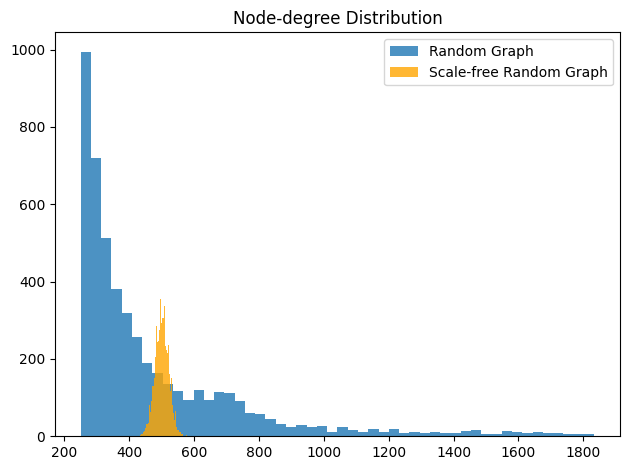

In [17]:
plt.title("Node-degree Distribution")
plt.hist(degrees2, 50, label="Random Graph", alpha=0.8)
plt.hist(degrees, 50, label="Scale-free Random Graph", color="orange", alpha=0.8)
plt.legend()
plt.tight_layout()
plt.show()

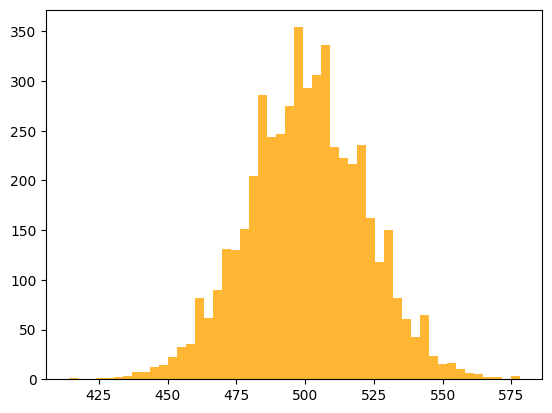

In [9]:
plt.hist(degrees, 50, label="Random Graph", color="orange", alpha=0.8)
plt.show()

In [4]:
data2.edge_index.shape[1]/(data2.x.shape[0]**2)

0.095

In [5]:
data1.edge_index.shape[1]/(data1.x.shape[0]**2)

0.10010324

In [14]:
torch.sum(degrees)/torch.sum(degrees2)

tensor(1.0537)